# 04 — Regression, Interactions, and Residual Analysis

This notebook preserves the project's core municipality-level statistical modeling.

It includes the fuel-only regression, addition of heating-electricity intensity, cooling-electricity extensions where present, interaction analysis, standardized coefficients, residual-based over/underperformer identification, and clustering work from the original regression notebook.


## Source provenance

This polished notebook consolidates the following original work:

- `regression(1).ipynb` — Core OLS regression progression, interaction models, standardized coefficients, predicted adoption, residual analysis, over/underperforming towns, and clustering.

No analytical code from the source files was silently replaced. The purpose of this version is to make the workflow easier to follow in a public research repository.


---
## Original analysis section: `regression(1).ipynb`

**What this section contains:** Core OLS regression progression, interaction models, standardized coefficients, predicted adoption, residual analysis, over/underperforming towns, and clustering.

> The code and outputs below are preserved from the original notebook/work file. They have not been rewritten or re-derived for this polished repository version.


In [1]:
from google.colab import files
uploaded = files.upload()

Saving final_with_cdd.csv to final_with_cdd.csv


In [2]:
import pandas as pd

final_df = pd.read_csv("final_with_cdd.csv")
final_df.head()

,municipality,total_households_2023,electric_fuel_2023,gas_fuel_2023,delivered_fuels_2023,electric_share_2023,gas_share_2023,delivered_share_2023,installs_per_1000_2023,total_households_2024,...,installs_per_1000_full_disp_2024,hp_accounts_full_disp_2024,summer_cdd_2013,summer_cdd_2023,summer_cdd_2024,summer_mwh_2013,summer_mwh_2023,summer_mwh_2024,elec_per_hh_per_cdd_2023,elec_per_hh_per_cdd_2024
0,wellfleet,1924,236,72,1400,0.122661,0.037422,0.727651,295.738046,2069,...,66.698888,138.0,442.335602,393.047241,512.838081,8392.0,7541.0,7196.0,0.009972,0.006782
1,oak bluffs,2064,259,167,1424,0.125484,0.080911,0.689922,156.492248,1944,...,56.069959,109.0,442.335602,393.047241,512.838081,16166.0,10619.0,10730.0,0.013090,0.010763
2,tisbury,1886,293,0,1437,0.155355,0.000000,0.761930,165.959703,1912,...,53.870293,103.0,442.335602,393.047241,512.838081,12022.0,8039.0,8265.0,0.010845,0.008429
3,eastham,2860,463,1170,1214,0.161888,0.409091,0.424476,219.930070,3041,...,49.325880,150.0,442.335602,393.047241,512.838081,12955.0,11216.0,11202.0,0.009978,0.007183
4,dennis,7116,1181,4878,1016,0.165964,0.685497,0.142777,147.414278,7302,...,34.237195,250.0,442.335602,393.047241,512.838081,38766.0,28066.0,29116.0,0.010035,0.007775


In [3]:
final_df.columns

Index(['municipality', 'total_households_2023', 'electric_fuel_2023',
       'gas_fuel_2023', 'delivered_fuels_2023', 'electric_share_2023',
       'gas_share_2023', 'delivered_share_2023', 'installs_per_1000_2023',
       'total_households_2024', 'electric_fuel_2024', 'gas_fuel_2024',
       'delivered_fuels_2024', 'electric_share_2024', 'gas_share_2024',
       'delivered_share_2024', 'installs_per_1000_2024',
       'electric_share_change_23_24', 'gas_share_change_23_24',
       'delivered_share_change_23_24', 'adoption_change_23_24',
       'total_households_2013', 'electric_fuel_2013', 'gas_fuel_2013',
       'delivered_fuels_2013', 'electric_share_2013', 'gas_share_2013',
       'delivered_share_2013', 'delivered_share_change_13_23',
       'gas_share_change_13_23', 'electric_share_change_13_23',
       'delivered_share_change_13_24', 'gas_share_change_13_24',
       'electric_share_change_13_24', 'wsr_2013', 'wsr_2023', 'wsr_2024',
       'winter_mwh_2013', 'winter_mwh_2023', 'w

In [5]:
import pandas as pd
import numpy as np

model_df = final_df.copy()

cols_needed = [
    "municipality",
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023",
    "installs_per_1000_full_disp_2024"
]

model_df = model_df[cols_needed].dropna()

model_df.shape

(101, 6)

In [6]:
import statsmodels.api as sm

y = model_df["installs_per_1000_full_disp_2024"]

X1 = model_df[[
    "delivered_share_2013",
    "gas_share_2013"
]]

X1 = sm.add_constant(X1)

model1 = sm.OLS(y, X1).fit()
print(model1.summary())

                                   OLS Regression Results                                   
Dep. Variable:     installs_per_1000_full_disp_2024   R-squared:                       0.397
Model:                                          OLS   Adj. R-squared:                  0.384
Method:                               Least Squares   F-statistic:                     32.20
Date:                              Wed, 06 May 2026   Prob (F-statistic):           1.79e-11
Time:                                      13:07:58   Log-Likelihood:                -358.31
No. Observations:                               101   AIC:                             722.6
Df Residuals:                                    98   BIC:                             730.5
Df Model:                                         2                                         
Covariance Type:                          nonrobust                                         
                           coef    std err          t      P>|t|      

In [7]:
X2 = model_df[[
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023"
]]

X2 = sm.add_constant(X2)

model2 = sm.OLS(y, X2).fit()
print(model2.summary())

                                   OLS Regression Results                                   
Dep. Variable:     installs_per_1000_full_disp_2024   R-squared:                       0.594
Model:                                          OLS   Adj. R-squared:                  0.581
Method:                               Least Squares   F-statistic:                     47.25
Date:                              Wed, 06 May 2026   Prob (F-statistic):           6.57e-19
Time:                                      13:13:09   Log-Likelihood:                -338.34
No. Observations:                               101   AIC:                             684.7
Df Residuals:                                    97   BIC:                             695.1
Df Model:                                         3                                         
Covariance Type:                          nonrobust                                         
                               coef    std err          t      P>|t|  

In [8]:
print("Model 1 R² fuel only:", model1.rsquared)
print("Model 2 R² fuel + HDD:", model2.rsquared)
print("Increase in R²:", model2.rsquared - model1.rsquared)

Model 1 R² fuel only: 0.39652659104886767
Model 2 R² fuel + HDD: 0.5937013177032453
Increase in R²: 0.19717472665437763


In [9]:
X3 = model_df[[
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]]

X3 = sm.add_constant(X3)

model3 = sm.OLS(y, X3).fit()
print(model3.summary())

                                   OLS Regression Results                                   
Dep. Variable:     installs_per_1000_full_disp_2024   R-squared:                       0.655
Model:                                          OLS   Adj. R-squared:                  0.640
Method:                               Least Squares   F-statistic:                     45.49
Date:                              Wed, 06 May 2026   Prob (F-statistic):           2.24e-21
Time:                                      13:14:05   Log-Likelihood:                -330.14
No. Observations:                               101   AIC:                             670.3
Df Residuals:                                    96   BIC:                             683.3
Df Model:                                         4                                         
Covariance Type:                          nonrobust                                         
                               coef    std err          t      P>|t|  

In [10]:
print("Model 1 R² fuel only:", model1.rsquared)
print("Model 2 R² fuel + HDD:", model2.rsquared)
print("Model 3 R² fuel + HDD + CDD:", model3.rsquared)

print("CDD added R²:", model3.rsquared - model2.rsquared)

Model 1 R² fuel only: 0.39652659104886767
Model 2 R² fuel + HDD: 0.5937013177032453
Model 3 R² fuel + HDD + CDD: 0.6546020199552196
CDD added R²: 0.060900702251974304


In [11]:
model_df["hdd_x_oil"] = (
    model_df["elec_per_hh_per_hdd_2023"] *
    model_df["delivered_share_2013"]
)

X4 = model_df[[
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "hdd_x_oil"
]]

X4 = sm.add_constant(X4)

model4 = sm.OLS(y, X4).fit()
print(model4.summary())

                                   OLS Regression Results                                   
Dep. Variable:     installs_per_1000_full_disp_2024   R-squared:                       0.620
Model:                                          OLS   Adj. R-squared:                  0.604
Method:                               Least Squares   F-statistic:                     39.16
Date:                              Wed, 06 May 2026   Prob (F-statistic):           2.08e-19
Time:                                      13:14:45   Log-Likelihood:                -334.96
No. Observations:                               101   AIC:                             679.9
Df Residuals:                                    96   BIC:                             693.0
Df Model:                                         4                                         
Covariance Type:                          nonrobust                                         
                               coef    std err          t      P>|t|  

In [12]:
print("Model 2 R² fuel + HDD:", model2.rsquared)
print("Model 4 R² interaction:", model4.rsquared)
print("Interaction added R²:", model4.rsquared - model2.rsquared)

Model 2 R² fuel + HDD: 0.5937013177032453
Model 4 R² interaction: 0.619992231305166
Interaction added R²: 0.026290913601920707


In [13]:
from sklearn.preprocessing import StandardScaler

features = [
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]

X_scaled = StandardScaler().fit_transform(model_df[features])
X_scaled = sm.add_constant(X_scaled)

model_scaled = sm.OLS(y, X_scaled).fit()

coef_table = pd.DataFrame({
    "variable": ["const"] + features,
    "standardized_coef": model_scaled.params
})

coef_table

,variable,standardized_coef
const,const,18.129825
x1,delivered_share_2013,3.275535
x2,gas_share_2013,-1.223836
x3,elec_per_hh_per_hdd_2023,1.872612
x4,elec_per_hh_per_cdd_2023,4.741269


In [14]:
coef_table.iloc[1:].sort_values(
    "standardized_coef",
    key=abs,
    ascending=False
)

,variable,standardized_coef
x4,elec_per_hh_per_cdd_2023,4.741269
x1,delivered_share_2013,3.275535
x3,elec_per_hh_per_hdd_2023,1.872612
x2,gas_share_2013,-1.223836


In [15]:
model_df["predicted_adoption"] = model3.predict(X3)
model_df["residual"] = model_df["installs_per_1000_full_disp_2024"] - model_df["predicted_adoption"]

In [16]:
overperformers = model_df.sort_values("residual", ascending=False).head(15)

overperformers[[
    "municipality",
    "installs_per_1000_full_disp_2024",
    "predicted_adoption",
    "residual",
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]]

,municipality,installs_per_1000_full_disp_2024,predicted_adoption,residual,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
0,wellfleet,66.698888,44.412979,22.285909,0.805210,0.046181,0.001024,0.009972
3,eastham,49.325880,34.309381,15.016498,0.480728,0.398874,0.000960,0.009978
22,ashland,23.420123,11.105454,12.314669,0.296777,0.616980,0.000647,0.003844
29,fairhaven,22.287637,10.805997,11.481640,0.226897,0.678738,0.000545,0.004965
15,grafton,25.731452,15.077195,10.654258,0.377385,0.463937,0.000726,0.004002
37,northampton,20.420287,10.034023,10.386263,0.307419,0.480413,0.000571,0.003217
30,arlington,22.194451,11.943579,10.250872,0.329677,0.562821,0.000563,0.004093
19,yarmouth,24.024778,14.039438,9.985341,0.140389,0.760928,0.000700,0.006701
31,maynard,21.779714,12.026934,9.752780,0.278215,0.624422,0.000603,0.004606
10,bourne,28.195911,18.462355,9.733556,0.340127,0.571642,0.000680,0.006273


In [17]:
underperformers = model_df.sort_values("residual", ascending=True).head(15)

underperformers[[
    "municipality",
    "installs_per_1000_full_disp_2024",
    "predicted_adoption",
    "residual",
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]]

,municipality,installs_per_1000_full_disp_2024,predicted_adoption,residual,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
94,pittsfield,6.406971,19.160825,-12.753854,0.391300,0.489708,0.000596,0.006213
71,walpole,11.416987,23.517933,-12.100946,0.417326,0.497304,0.000801,0.006970
65,franklin,12.368634,23.255375,-10.886741,0.285092,0.581169,0.000611,0.009106
75,stoneham,10.770335,20.567969,-9.797633,0.464935,0.349294,0.000677,0.005385
70,attleboro,11.431439,21.140658,-9.709219,0.473662,0.345872,0.000723,0.005344
53,needham,15.535992,25.095507,-9.559516,0.460690,0.436829,0.000843,0.006888
36,sudbury,20.485946,29.871475,-9.385529,0.400830,0.562684,0.001096,0.008745
74,andover,11.054294,19.553904,-8.499610,0.321473,0.558140,0.000778,0.006451
77,saugus,10.312101,18.661871,-8.349770,0.370858,0.478105,0.000714,0.005661
86,north andover,8.661008,16.552037,-7.891028,0.267523,0.583928,0.000757,0.005841


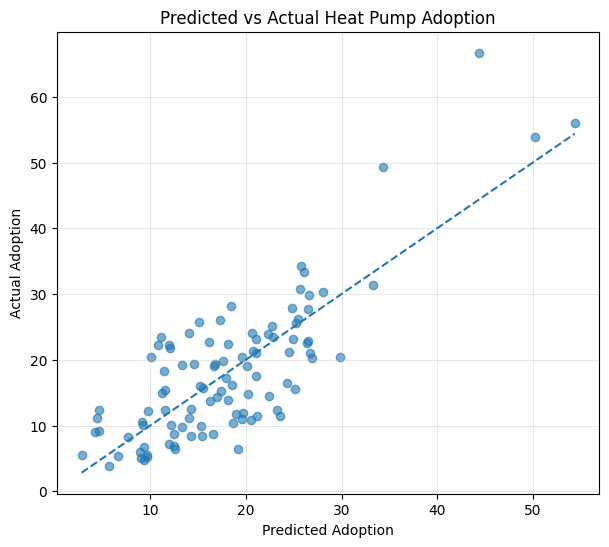

In [18]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7,6))

plt.scatter(
    model_df["predicted_adoption"],
    model_df["installs_per_1000_full_disp_2024"],
    alpha=0.6
)

plt.plot(
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    linestyle="--"
)

plt.xlabel("Predicted Adoption")
plt.ylabel("Actual Adoption")
plt.title("Predicted vs Actual Heat Pump Adoption")
plt.grid(alpha=0.3)
plt.show()

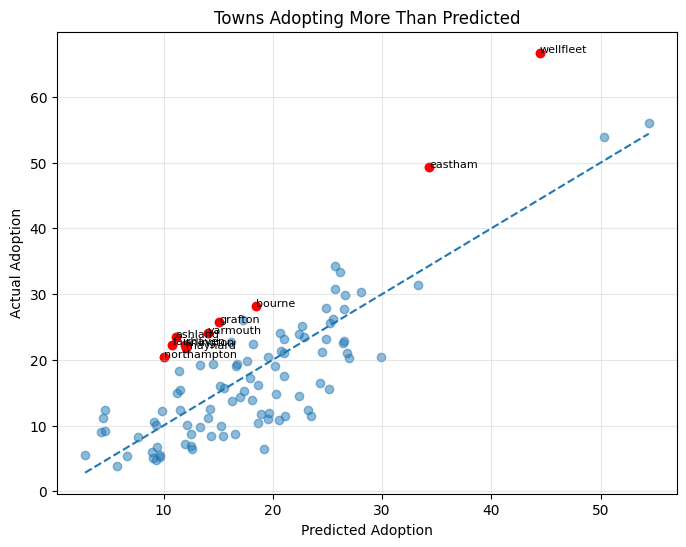

In [19]:
top_over = model_df.sort_values("residual", ascending=False).head(10)

plt.figure(figsize=(8,6))

plt.scatter(
    model_df["predicted_adoption"],
    model_df["installs_per_1000_full_disp_2024"],
    alpha=0.5
)

plt.plot(
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    linestyle="--"
)

plt.scatter(
    top_over["predicted_adoption"],
    top_over["installs_per_1000_full_disp_2024"],
    color="red"
)

for _, row in top_over.iterrows():
    plt.text(
        row["predicted_adoption"],
        row["installs_per_1000_full_disp_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Predicted Adoption")
plt.ylabel("Actual Adoption")
plt.title("Towns Adopting More Than Predicted")
plt.grid(alpha=0.3)
plt.show()

In [20]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

cluster_features = [
    "delivered_share_2013",
    "gas_share_2013",
    "elec_per_hh_per_hdd_2023",
    "elec_per_hh_per_cdd_2023"
]

cluster_df = model_df.dropna(subset=cluster_features).copy()

scaler = StandardScaler()
X_cluster = scaler.fit_transform(cluster_df[cluster_features])

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_df["cluster"] = kmeans.fit_predict(X_cluster)

cluster_df.head()

,municipality,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023,installs_per_1000_full_disp_2024,hdd_x_oil,predicted_adoption,residual,cluster
0,wellfleet,0.805210,0.046181,0.001024,0.009972,66.698888,0.000825,44.412979,22.285909,2
1,oak bluffs,0.656869,0.074985,0.001622,0.013090,56.069959,0.001066,54.383244,1.686714,2
2,tisbury,0.777692,0.020914,0.001446,0.010845,53.870293,0.001125,50.272626,3.597667,2
3,eastham,0.480728,0.398874,0.000960,0.009978,49.325880,0.000461,34.309381,15.016498,0
4,dennis,0.195338,0.678647,0.000899,0.010035,34.237195,0.000176,25.720626,8.516569,0


In [21]:
cluster_summary = cluster_df.groupby("cluster").agg(
    towns=("municipality", "count"),
    avg_adoption=("installs_per_1000_full_disp_2024", "mean"),
    avg_delivered_share=("delivered_share_2013", "mean"),
    avg_gas_share=("gas_share_2013", "mean"),
    avg_hdd_intensity=("elec_per_hh_per_hdd_2023", "mean"),
    avg_cdd_intensity=("elec_per_hh_per_cdd_2023", "mean")
).reset_index()

cluster_summary

,cluster,towns,avg_adoption,avg_delivered_share,avg_gas_share,avg_hdd_intensity,avg_cdd_intensity
0,0,45,20.481389,0.402156,0.469204,0.000793,0.006504
1,1,47,12.292051,0.261139,0.589617,0.000594,0.004378
2,2,9,36.858155,0.705277,0.085491,0.001014,0.006532


In [22]:
cluster_summary.sort_values("avg_adoption", ascending=False)

,cluster,towns,avg_adoption,avg_delivered_share,avg_gas_share,avg_hdd_intensity,avg_cdd_intensity
2,2,9,36.858155,0.705277,0.085491,0.001014,0.006532
0,0,45,20.481389,0.402156,0.469204,0.000793,0.006504
1,1,47,12.292051,0.261139,0.589617,0.000594,0.004378


In [23]:
for c in sorted(cluster_df["cluster"].unique()):
    print("\nCluster", c)
    display(
        cluster_df[cluster_df["cluster"] == c][[
            "municipality",
            "installs_per_1000_full_disp_2024",
            "delivered_share_2013",
            "gas_share_2013",
            "elec_per_hh_per_hdd_2023",
            "elec_per_hh_per_cdd_2023"
        ]].sort_values("installs_per_1000_full_disp_2024", ascending=False).head(10)
    )


Cluster 0


,municipality,installs_per_1000_full_disp_2024,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
3,eastham,49.325880,0.480728,0.398874,0.000960,0.009978
4,dennis,34.237195,0.195338,0.678647,0.000899,0.010035
6,brewster,31.363345,0.515832,0.339792,0.001014,0.008830
7,sandwich,30.812989,0.453986,0.457464,0.000823,0.007348
8,falmouth,30.288784,0.415759,0.495473,0.000847,0.008686
10,bourne,28.195911,0.340127,0.571642,0.000680,0.006273
11,montague,27.946217,0.496097,0.305787,0.000657,0.006851
12,wayland,27.657053,0.353265,0.564713,0.001078,0.007847
13,harwich,26.274632,0.300332,0.601773,0.000854,0.008932
14,holliston,26.038001,0.409268,0.482264,0.000782,0.004458



Cluster 1


,municipality,installs_per_1000_full_disp_2024,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
15,grafton,25.731452,0.377385,0.463937,0.000726,0.004002
19,yarmouth,24.024778,0.140389,0.760928,0.000700,0.006701
22,ashland,23.420123,0.296777,0.616980,0.000647,0.003844
29,fairhaven,22.287637,0.226897,0.678738,0.000545,0.004965
30,arlington,22.194451,0.329677,0.562821,0.000563,0.004093
31,maynard,21.779714,0.278215,0.624422,0.000603,0.004606
37,northampton,20.420287,0.307419,0.480413,0.000571,0.003217
41,framingham,19.400813,0.278178,0.458624,0.000686,0.004840
42,westford,19.329164,0.236498,0.713984,0.000799,0.006418
43,melrose,19.272639,0.344001,0.535589,0.000573,0.004420



Cluster 2


,municipality,installs_per_1000_full_disp_2024,delivered_share_2013,gas_share_2013,elec_per_hh_per_hdd_2023,elec_per_hh_per_cdd_2023
0,wellfleet,66.698888,0.805210,0.046181,0.001024,0.009972
1,oak bluffs,56.069959,0.656869,0.074985,0.001622,0.013090
2,tisbury,53.870293,0.777692,0.020914,0.001446,0.010845
5,rutland,33.281005,0.703704,0.019435,0.000820,0.003976
9,southborough,29.917924,0.606246,0.333435,0.000943,0.005464
16,belchertown,25.628469,0.659538,0.029493,0.000733,0.004413
21,auburn,23.429492,0.669015,0.161890,0.000777,0.003515
27,athol,22.534014,0.798094,0.036612,0.000800,0.003372
39,oxford,20.293349,0.671130,0.046475,0.000955,0.004144


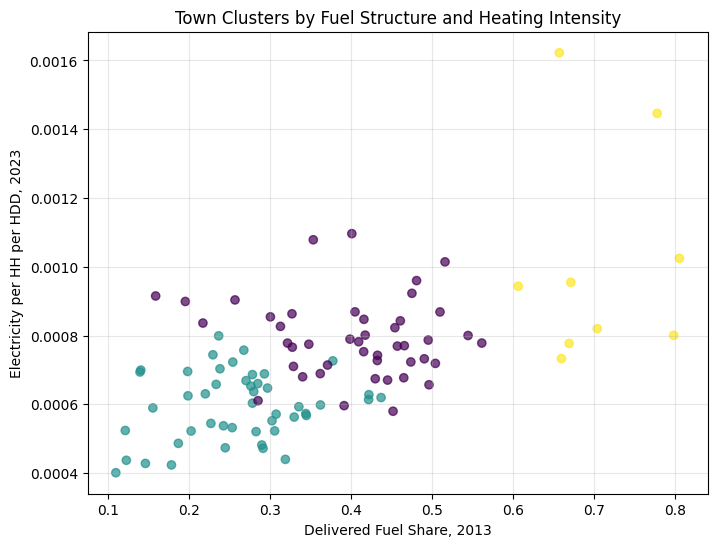

In [24]:
plt.figure(figsize=(8,6))

plt.scatter(
    cluster_df["delivered_share_2013"],
    cluster_df["elec_per_hh_per_hdd_2023"],
    c=cluster_df["cluster"],
    alpha=0.7
)

plt.xlabel("Delivered Fuel Share, 2013")
plt.ylabel("Electricity per HH per HDD, 2023")
plt.title("Town Clusters by Fuel Structure and Heating Intensity")
plt.grid(alpha=0.3)
plt.show()

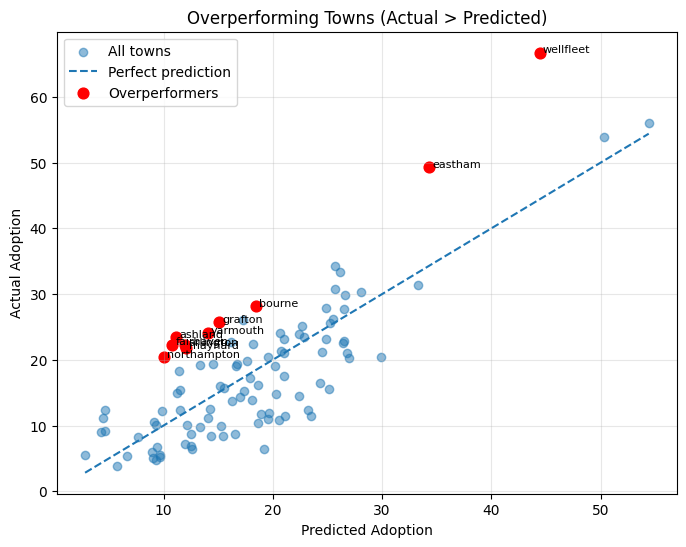

In [25]:
import matplotlib.pyplot as plt

# Select top overperforming towns
top_over = model_df.sort_values("residual", ascending=False).head(10)

plt.figure(figsize=(8,6))

# All towns
plt.scatter(
    model_df["predicted_adoption"],
    model_df["installs_per_1000_full_disp_2024"],
    alpha=0.5,
    label="All towns"
)

# Perfect prediction line
plt.plot(
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    linestyle="--",
    label="Perfect prediction"
)

# Highlight overperformers
plt.scatter(
    top_over["predicted_adoption"],
    top_over["installs_per_1000_full_disp_2024"],
    color="red",
    s=60,
    label="Overperformers"
)

# Label towns
for _, row in top_over.iterrows():
    plt.text(
        row["predicted_adoption"] + 0.3,
        row["installs_per_1000_full_disp_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Predicted Adoption")
plt.ylabel("Actual Adoption")
plt.title("Overperforming Towns (Actual > Predicted)")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

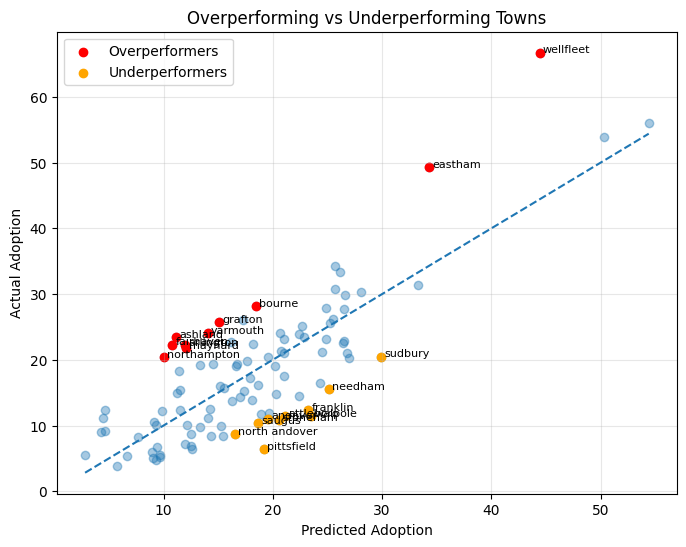

In [26]:
import matplotlib.pyplot as plt

# Top overperformers
top_over = model_df.sort_values("residual", ascending=False).head(10)

# Top underperformers
bottom_under = model_df.sort_values("residual", ascending=True).head(10)

plt.figure(figsize=(8,6))

# All towns
plt.scatter(
    model_df["predicted_adoption"],
    model_df["installs_per_1000_full_disp_2024"],
    alpha=0.4
)

# Perfect line
plt.plot(
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    [model_df["predicted_adoption"].min(), model_df["predicted_adoption"].max()],
    linestyle="--"
)

# Overperformers (red)
plt.scatter(
    top_over["predicted_adoption"],
    top_over["installs_per_1000_full_disp_2024"],
    color="red",
    label="Overperformers"
)

# Underperformers (orange)
plt.scatter(
    bottom_under["predicted_adoption"],
    bottom_under["installs_per_1000_full_disp_2024"],
    color="orange",
    label="Underperformers"
)

# Labels
for _, row in top_over.iterrows():
    plt.text(
        row["predicted_adoption"] + 0.3,
        row["installs_per_1000_full_disp_2024"],
        row["municipality"],
        fontsize=8
    )

for _, row in bottom_under.iterrows():
    plt.text(
        row["predicted_adoption"] + 0.3,
        row["installs_per_1000_full_disp_2024"],
        row["municipality"],
        fontsize=8
    )

plt.xlabel("Predicted Adoption")
plt.ylabel("Actual Adoption")
plt.title("Overperforming vs Underperforming Towns")
plt.legend()
plt.grid(alpha=0.3)

plt.show()